# Hard facts: 180 natural-language questions

Validate the frozen CSV, run the actual anime RAG, and evaluate requested facts.
**180 authored English prompts across 76 anime; no repeated question or anime/field pair.**
These are naturalistic synthetic questions, not user logs or an external question dataset.
Popular titles are overrepresented; this is not a representative sample of user traffic.

Seven fields: release **year**, episode count, minutes per episode, format, source medium,
main animation studios, and main characters. Full calendar dates, unknown-answer
abstention, conversational memory, and recommendations are outside this benchmark.
See `data/evaluation/hard_facts/README.md` for provenance and definitions.

In [1]:
from pathlib import Path
from collections import Counter
import csv
import hashlib
import json
import os
import subprocess
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/recommender/factual_evaluation.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open the notebook from the repository root or notebook directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string(index=False) if hasattr(value, 'to_string') else value)
from src.recommender.config import load_settings
from src.recommender.factual_evaluation import load_questions, read_csv, score_values

DATA = ROOT / 'data/evaluation/hard_facts'
QUESTIONS_CSV = DATA / 'questions.csv'
SETTINGS = load_settings(ROOT / 'recommender.toml', 'anilist')
DATABASE = SETTINGS.documents / 'catalog.sqlite3'
PROJECT_PYTHON = ROOT / '.venv' / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
if not PROJECT_PYTHON.is_file():
    PROJECT_PYTHON = Path(sys.executable)
manifest = json.loads((DATA / 'dataset_manifest.json').read_text(encoding='utf-8'))
questions = load_questions(QUESTIONS_CSV, DATABASE if DATABASE.is_file() else None)
frame = pd.DataFrame(questions)
print(f'{len(questions)} questions | {frame.anime_id.nunique()} anime | {frame.field.nunique()} fields')
print('Notebook kernel:', sys.executable)
print('Live evaluation interpreter:', PROJECT_PYTHON)

180 questions | 76 anime | 7 fields
Notebook kernel: C:\Users\muham\Documents\LLM Proj\rag-in-production\.venv\Scripts\python.exe
Live evaluation interpreter: C:\Users\muham\Documents\LLM Proj\rag-in-production\.venv\Scripts\python.exe


## Dataset integrity and coverage

Labels are independently queried from the imported local snapshot, not live websites.
Studios require both `main=true` and `animation=true`; characters require role `MAIN`.
Season-specific entries are scored separately. Rebuilding labels is an intentional
versioning operation, never part of evaluation. References below are for inspection;
they are not passed to the RAG or the claim extractor.

In [2]:
assert len(questions) == manifest['question_count'] == 180
assert frame.question_id.is_unique and frame.question.str.casefold().is_unique
assert not frame.duplicated(['anime_id', 'field']).any()
assert frame.anime_id.nunique() == manifest['unique_anime']
assert hashlib.sha256(QUESTIONS_CSV.read_bytes()).hexdigest() == manifest['questions_sha256']
evidence = [{'question_id': q['question_id'], 'anime_id': q['anime_id'],
             'field': q['field'], 'values': json.loads(q['expected_values'])} for q in questions]
assert hashlib.sha256(json.dumps(evidence, sort_keys=True, ensure_ascii=False).encode()).hexdigest() == manifest['labels_sha256']
assert Counter(frame.field) == manifest['by_field']
assert frame.question_origin.eq('authored_naturalistic').all()
display(frame.groupby('field').agg(questions=('question_id', 'size'), anime=('anime_id', 'nunique')).reset_index())
display(frame.groupby('field', sort=False).head(2)[['question_id', 'field', 'question', 'expected_values']])
if DATABASE.is_file():
    print('All frozen labels match:', DATABASE)
else:
    print('Frozen input hashes verified. Database comparison is available after AniList setup; offline inspection needs no bulk data.')

,field,questions,anime
0,duration,26,26
1,episodes,26,26
2,format,26,26
3,main_animation_studios,25,25
4,main_characters,25,25
5,source_material,26,26
6,year,26,26


,question_id,field,question,expected_values
0,hf_001,year,What year did the first season of Attack on Ti...,[2013.0]
1,hf_002,year,When did Demon Slayer first come out? Just the...,[2019.0]
26,hf_027,episodes,How many episodes are in Hunter x Hunter's 201...,[148.0]
27,hf_028,episodes,How long is Attack on Titan season two in epis...,[12.0]
52,hf_053,duration,About how many minutes is one episode of Demon...,[24.0]
53,hf_054,duration,What's the listed runtime per episode of JUJUT...,[24.0]
78,hf_079,format,Is A Silent Voice cataloged as a movie or a TV...,"[""MOVIE""]"
79,hf_080,format,What release format is Your Name listed under?,"[""MOVIE""]"
104,hf_105,source_material,What type of source material was Attack on Tit...,"[""MANGA""]"
105,hf_106,source_material,"Was A Silent Voice based on a manga, a novel, ...","[""MANGA""]"


All frozen labels match: C:\Users\muham\Documents\LLM Proj\rag-in-production\data\documents\anilist\catalog.sqlite3


## Dataset visualization

Coverage is shown for the complete CSV. Charts are rendered with matplotlib in the
project environment and saved as PNG and SVG, so the notebook kernel does not need
matplotlib. Install the chart dependencies once with `uv sync --extra evaluation`.

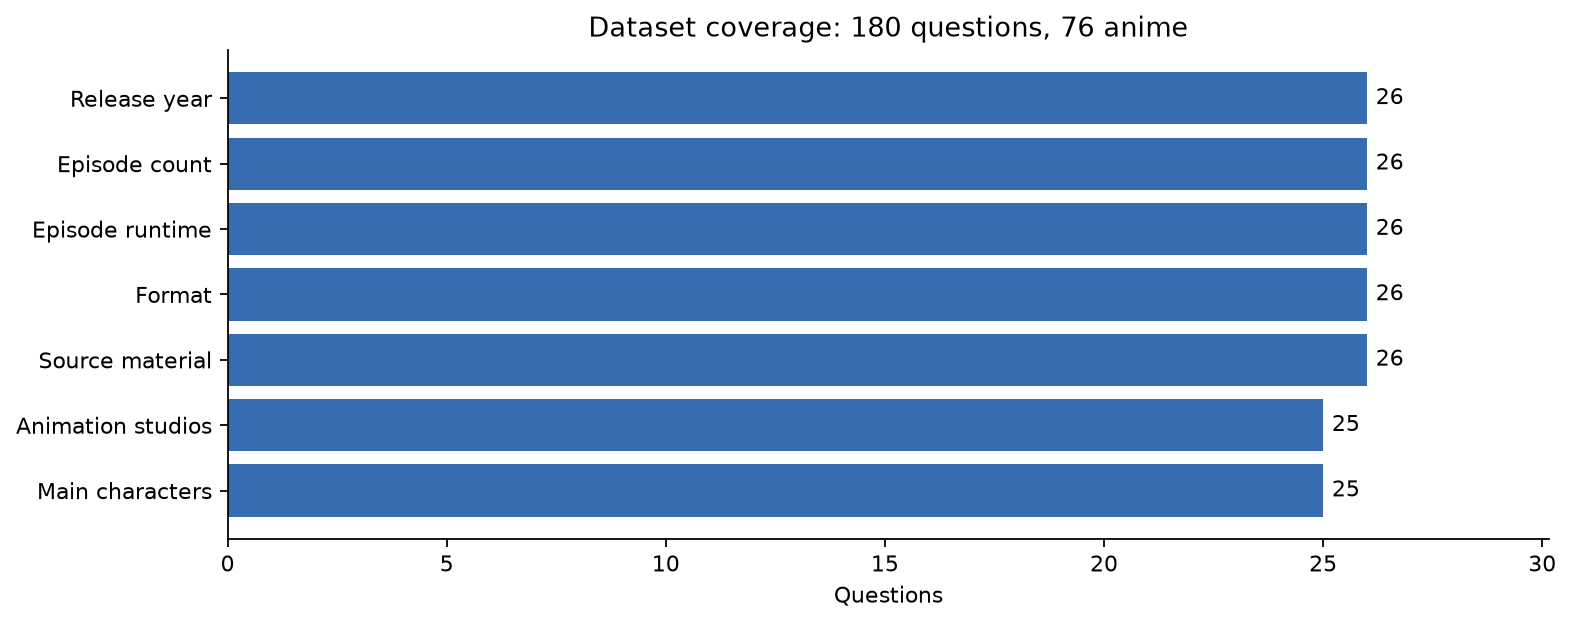

Full CSV coverage; independent of how many evaluation questions have been attempted.
PNG and SVG exports: C:\Users\muham\Documents\LLM Proj\rag-in-production\data\evaluation\hard_facts\charts


In [3]:
def show_evaluation_charts(results=None):
    chart_output = (Path(results) / 'charts') if results is not None else DATA / 'charts'
    command = [str(PROJECT_PYTHON), '-X', 'utf8', '-m', 'src.recommender.hard_facts_visualizations',
               '--questions', str(QUESTIONS_CSV), '--output', str(chart_output)]
    if results is not None:
        command.extend(['--results', str(results)])
    chart_environment = {**os.environ, 'MPLBACKEND': 'Agg', 'PYTHONIOENCODING': 'utf-8'}
    completed = subprocess.run(command, cwd=ROOT, env=chart_environment, capture_output=True, text=True,
                               encoding='utf-8', errors='replace')
    if completed.returncode:
        hint = 'Run uv sync --extra evaluation. ' if 'ModuleNotFoundError' in completed.stderr else ''
        raise RuntimeError('Chart rendering failed. ' + hint + 'Details: ' + completed.stderr)
    artifacts = json.loads((chart_output / 'charts.json').read_text(encoding='utf-8'))
    for artifact in artifacts:
        # The dataset-only view already displays this chart.
        if results is not None and Path(artifact['png']).stem == 'dataset_coverage':
            continue
        try:
            from IPython.display import Image
        except ImportError:
            print('Chart:', artifact['png'])
        else:
            display(Image(filename=artifact['png']))
        print(artifact['caption'])
    print('PNG and SVG exports:', chart_output)
    return artifacts

dataset_charts = show_evaluation_charts()

## Experiment configuration

This notebook selects **all 180 prompts**. The default displays the completed full
real-model run when available. Set `RUN_LIVE = True` to run or resume full inference;
choose a new `RUN_NAME` when changing the experiment configuration.
The notebook kernel needs pandas and Python 3.11 or newer. Live evaluation always runs
in the project's `.venv` interpreter, even when Jupyter uses a different Python.
This avoids importing incompatible global packages such as the obsolete `docx` package.
Ollama and prepared AniList indexes must already be available.
No setup rebuild or downloads are performed. A full run may take substantial time.

Each finished question is checkpointed. An identical run resumes, including failures;
use a fresh run name to retry or change configuration. `EXTRACTOR_MODEL` can name a
separately installed stronger model to reduce correlated generation/extraction errors.

In [4]:
RUN_LIVE = False
MODE = 'full'                # all 180 questions
RUN_NAME = 'entity_resolution_v1_parser_v3' # completed real full run; change for a new experiment
EXTRACTOR_MODEL = None        # defaults to SETTINGS.llm
MAX_NEW_QUESTIONS = None      # optional per-execution budget; None continues all missing prompts

if MODE != 'full':
    raise ValueError('This notebook evaluates all 180 benchmark questions.')
if not RUN_NAME or Path(RUN_NAME).name != RUN_NAME or RUN_NAME in {'.', '..'}:
    raise ValueError('RUN_NAME must be a single directory name')
selected = questions
RUN_QUESTIONS = QUESTIONS_CSV
OUTPUT = DATA / 'results' / RUN_NAME
print(f'Mode: {MODE}; selected: {len(selected)}; live inference: {RUN_LIVE}')
print('Generation:', SETTINGS.llm, '| Extractor:', EXTRACTOR_MODEL or SETTINGS.llm)
print('Output:', OUTPUT)

Mode: full; selected: 180; live inference: False
Generation: llama3.2:3b | Extractor: llama3.2:3b
Output: C:\Users\muham\Documents\LLM Proj\rag-in-production\data\evaluation\hard_facts\results\entity_resolution_v1_parser_v3


## Run inference and report accuracy

Only question text reaches `RagPipeline.ask`, with empty history and fresh agent state.
The extractor receives the question, requested field, and final answer; it never sees
reference values or catalog records. It parses asserted values through a dedicated LLM request. Code attaches the full original answer as evidence.
Deterministic set comparison penalizes missing and extra values; no fuzzy similarity.

**Primary metric: exact correct answers / all attempted questions.** Model errors,
extraction errors, and unclear extractions count as unsuccessful primary-metric attempts.
Macro value precision/recall/F1 apply to scored questions; unanswered answers score zero.
Always inspect scoring coverage. Only the requested field is evaluated, not every
additional prose claim. Startup is included in the first RAG latency; extraction is timed separately.

In [5]:
report, answers = None, []
if RUN_LIVE:
    if not DATABASE.is_file():
        raise RuntimeError('Complete AniList setup before live evaluation. Offline dataset inspection works without it.')
    command = [str(PROJECT_PYTHON), '-u', '-X', 'utf8', '-m', 'src.recommender.factual_evaluation',
               '--settings', str(ROOT / 'recommender.toml'),
               '--questions', str(RUN_QUESTIONS), '--output', str(OUTPUT)]
    if EXTRACTOR_MODEL:
        command.extend(['--extractor-model', EXTRACTOR_MODEL])
    if MAX_NEW_QUESTIONS is not None:
        command.extend(['--max-new-questions', str(MAX_NEW_QUESTIONS)])
    # Use the managed environment, never the notebook kernel's globally installed RAG dependencies.
    environment = {**os.environ, 'PYTHONIOENCODING': 'utf-8', 'PYTHONUNBUFFERED': '1'}
    process = subprocess.Popen(command, cwd=ROOT, env=environment, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace')
    try:
        for line in process.stdout:
            print(line, end='', flush=True)
        returncode = process.wait()
    except BaseException:
        process.terminate()
        try:
            process.wait(timeout=10)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()
        raise
    finally:
        process.stdout.close()
    if returncode:
        raise RuntimeError(f'Evaluation failed with exit code {returncode}; see the output above. Completed checkpoints are preserved.')
    report = json.loads((OUTPUT / 'summary.json').read_text(encoding='utf-8'))
elif (OUTPUT / 'summary.json').is_file():
    saved = json.loads((OUTPUT / 'manifest.json').read_text(encoding='utf-8'))
    assert saved['questions_sha256'] == hashlib.sha256(RUN_QUESTIONS.read_bytes()).hexdigest(), 'Saved dataset differs.'
    assert saved['question_ids'] == [q['question_id'] for q in selected], 'Saved selection differs.'
    report = json.loads((OUTPUT / 'summary.json').read_text(encoding='utf-8'))
    print('Displaying saved results; no live calls made during this notebook execution.')
else:
    print('No saved run. Set RUN_LIVE = True to collect actual RAG answers.')
if report is not None:
    answers = read_csv(OUTPUT / 'answers.csv')
    print(f"Actual attempts: {report['overall']['attempted']} / {len(selected)} selected / 180 total prompts")
    display(pd.DataFrame([report['overall']]).drop(columns=['status_counts']))
    print('Statuses:', report['overall']['status_counts'])
    display(pd.DataFrame([{'field': field, **metrics} for field, metrics in report['by_field'].items()]))

Displaying saved results; no live calls made during this notebook execution.
Actual attempts: 180 / 180 selected / 180 total prompts


,attempted,automatically_scored,end_to_end_exact_accuracy,scoring_coverage,scored_exact_accuracy,macro_precision,macro_recall,macro_f1,mean_model_seconds,mean_extraction_seconds
0,180,170,0.705556,0.944444,0.747059,0.787661,0.839706,0.80092,28.363585,0.840816


Statuses: {'answered': 169, 'model_error': 10, 'unanswered': 1}


,field,attempted,automatically_scored,status_counts,end_to_end_exact_accuracy,scoring_coverage,scored_exact_accuracy,macro_precision,macro_recall,macro_f1,mean_model_seconds,mean_extraction_seconds
0,duration,26,20,"{'answered': 20, 'model_error': 6}",0.192308,0.769231,0.250000,0.266667,0.300000,0.275000,29.966562,0.619883
1,episodes,26,24,"{'answered': 24, 'model_error': 2}",0.730769,0.923077,0.791667,0.854167,0.916667,0.875000,30.701759,0.725394
2,format,26,26,{'answered': 26},0.769231,1.000000,0.769231,0.788462,0.807692,0.794872,28.341233,0.731575
3,main_animation_studios,25,25,{'answered': 25},0.840000,1.000000,0.840000,0.856000,0.880000,0.862857,25.285642,0.746469
4,main_characters,25,23,"{'answered': 22, 'model_error': 2, 'unanswered...",0.760000,0.920000,0.826087,0.908075,0.945652,0.915286,27.156789,1.077724
5,source_material,26,26,{'answered': 26},0.653846,1.000000,0.653846,0.741667,0.923077,0.783333,27.738483,0.837203
6,year,26,26,{'answered': 26},1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,29.189829,1.152951


## Evaluation visualizations

Charts use the selected run's saved answers. Accuracy includes every attempted question;
value precision/recall/F1 include scored answers only. Missing scores remain unscored.
Outcome counts distinguish incorrect answers, unanswered questions, model errors,
extraction errors, and uncertain extractions. Latency includes failures and startup.
Every result chart reports attempted/total benchmark questions and labels partial runs.

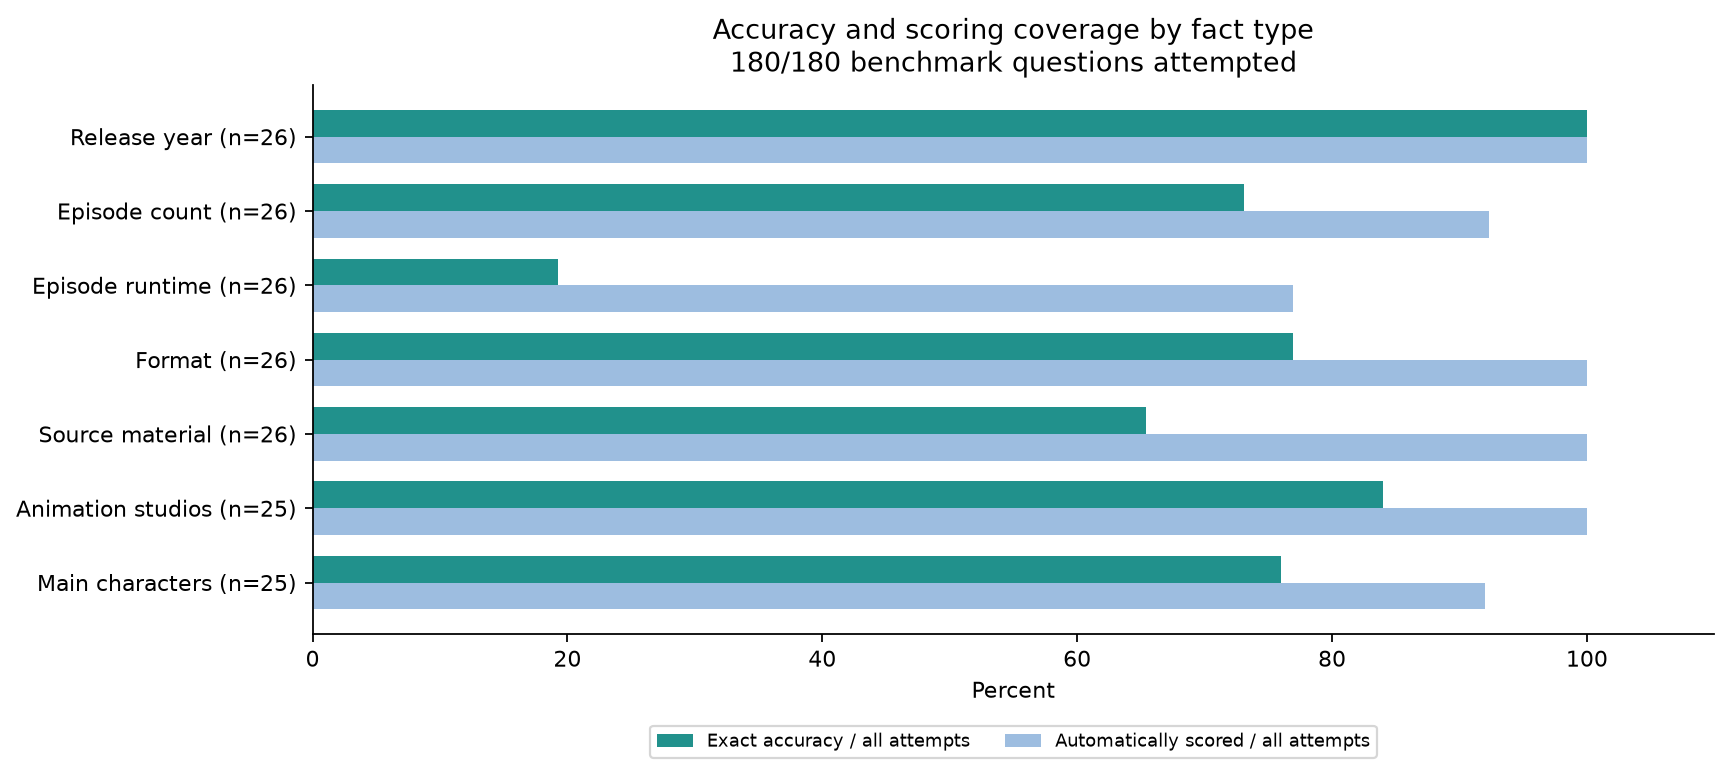

Errors remain in the accuracy denominator. Missing fields are omitted, not displayed as zero performance.


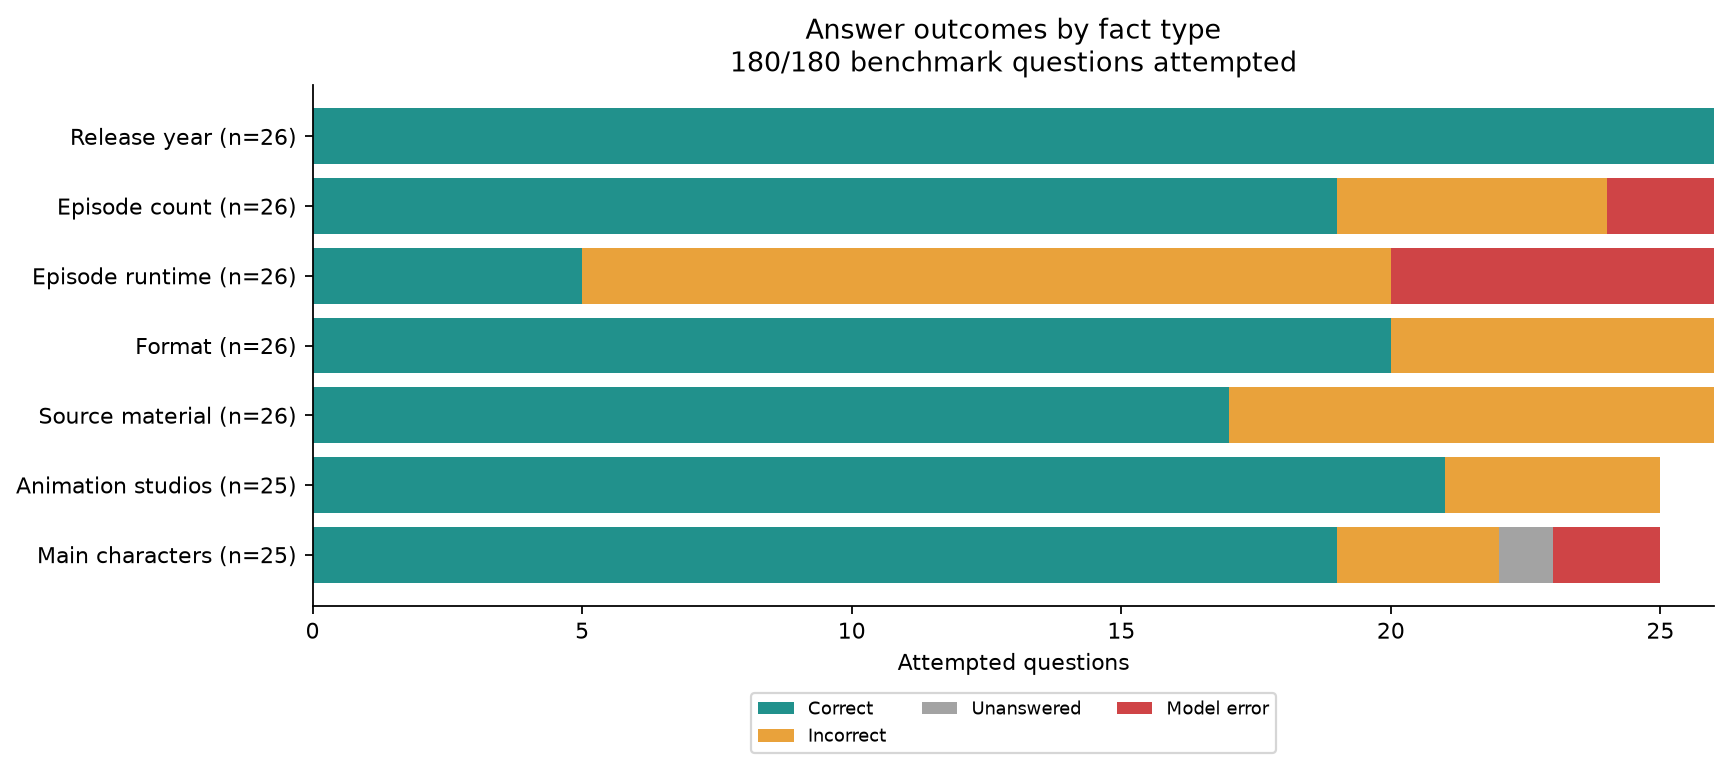

Counts distinguish factual mismatches from inference failures and uncertain extraction.


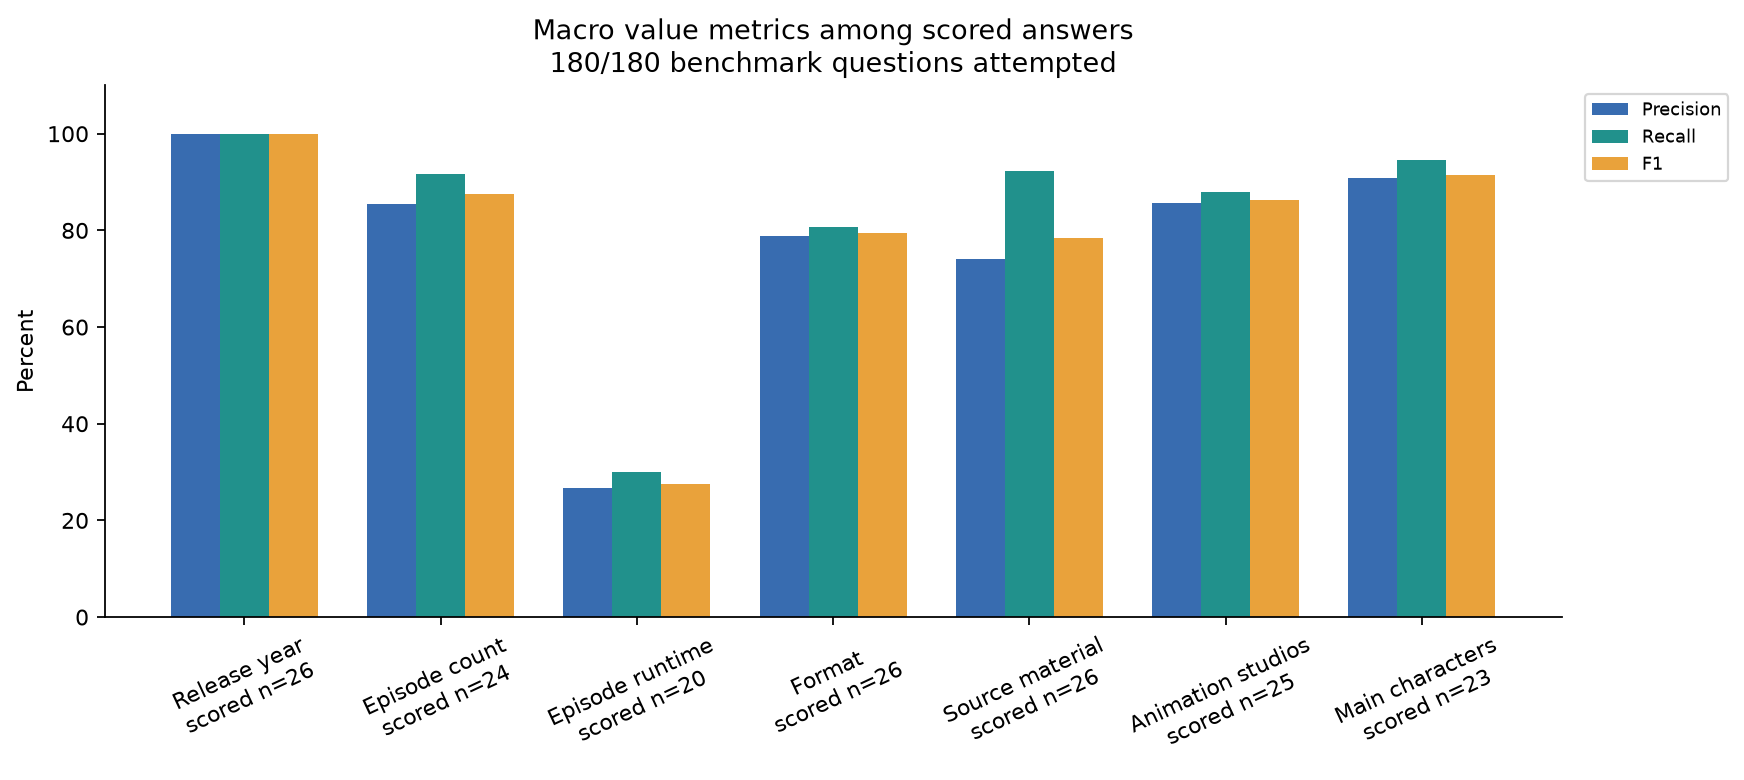

Precision penalizes extra values; recall penalizes missing values. Unscored groups have no bar, not a zero score.


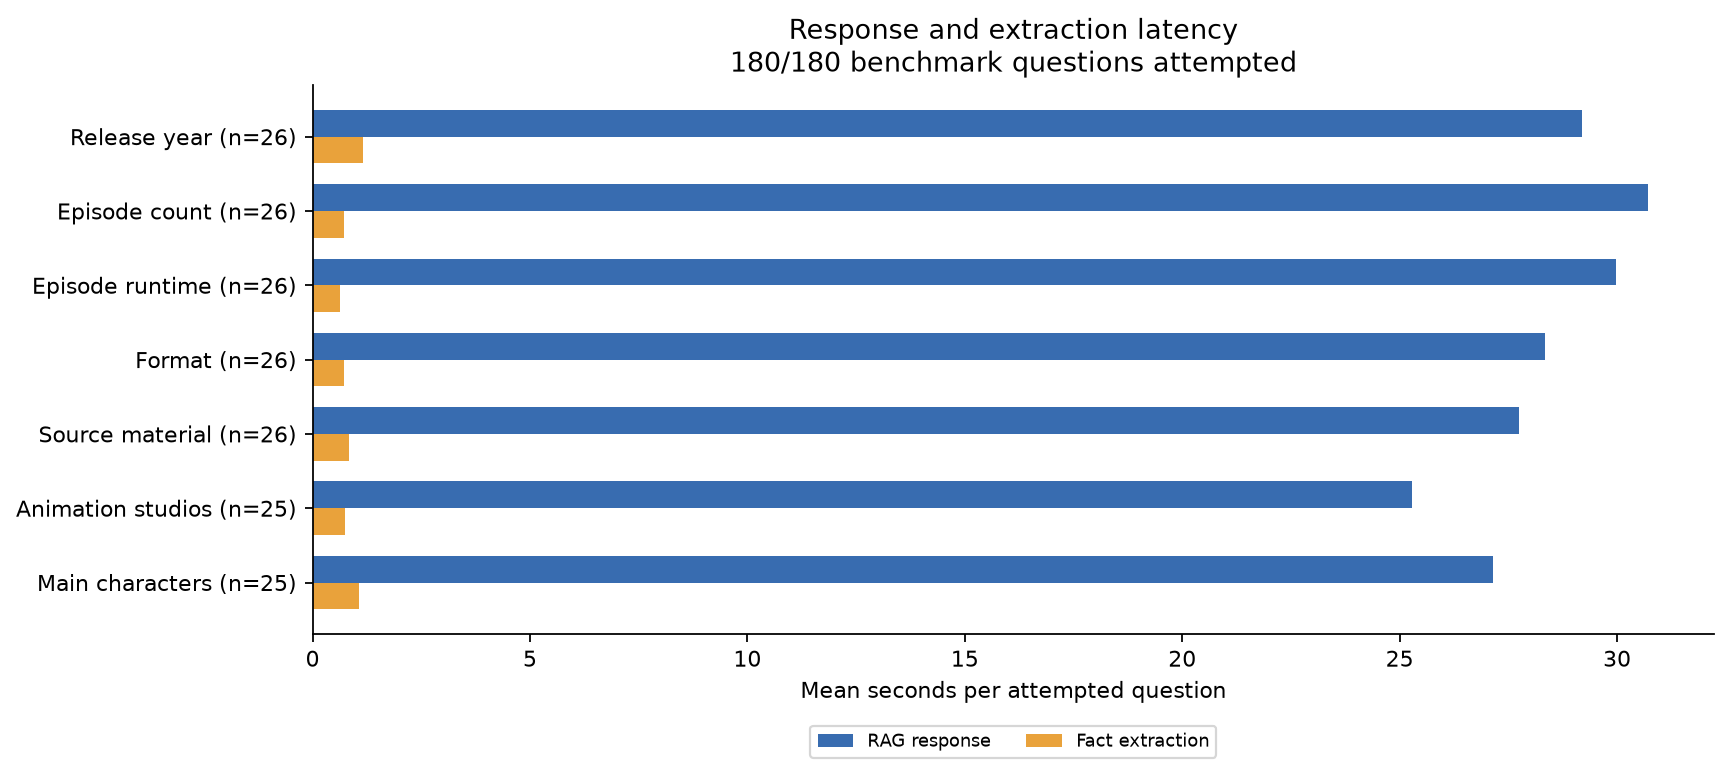

All attempts included; extraction is zero when generation failed. First-response latency includes model startup.
PNG and SVG exports: C:\Users\muham\Documents\LLM Proj\rag-in-production\data\evaluation\hard_facts\results\entity_resolution_v1_parser_v3\charts


In [6]:
if report is not None and answers:
    result_charts = show_evaluation_charts(OUTPUT)
else:
    print('No evaluated answers yet. Result charts will appear after collecting or loading a run.')

## Error analysis and extraction audit

Review failures and apparently correct answers. Retaining the original answer does not guarantee
correct extraction or entity association. A small model judging its own answers can
introduce correlated errors. Exact matching can reject unregistered valid aliases;
review and document alias changes rather than changing expected answers to fit outputs.

In [7]:
if answers:
    answer_frame = pd.DataFrame(answers)
    failed = answer_frame.loc[answer_frame.exact_match.ne('1')]
    display(failed[['question_id', 'field', 'question', 'answer_text', 'expected_values',
                    'extracted_values', 'status', 'error']])
    for row in answer_frame.groupby('field', sort=False).head(1).to_dict('records'):
        print('\n', row['question_id'], row['question'])
        print('ANSWER:', row['answer_text'])
        print('EXPECTED:', row['expected_values'], '| EXTRACTED:', row['extracted_values'])
        print('EXTRACTION AND QUOTES:', row['extraction'])
    print('Full answers:', OUTPUT / 'answers.csv')
else:
    print('Run an experiment before inspecting model errors.')

,question_id,field,question,answer_text,expected_values,extracted_values,status,error
29,hf_030,episodes,How many episodes does Attack on Titan Season ...,Attack on Titan Season 3: 25 episodes.,[12.0],"[""25""]",answered,
30,hf_031,episodes,How many episodes would I need to watch to fin...,episodes needed to finish My Hero Academia sea...,[25.0],"[""25"", ""episodes needed to finish My Hero Acad...",answered,
34,hf_035,episodes,How many episodes were made for My Hero Academ...,My Hero Academia's third season: 13 episodes.,[25.0],"[""13""]",answered,
37,hf_038,episodes,How many episodes are in the first SPY x FAMIL...,,[12.0],[],model_error,RuntimeError: The model returned an invalid gr...
38,hf_039,episodes,How many episodes does the first Kaguya-sama: ...,The first season of Kaguya-sama: Love is War c...,[12.0],"[""12"", ""12 episodes""]",answered,
45,hf_046,episodes,How many episodes aired in the first season of...,The Seven Deadly Sins: 24 episodes.,[24.0],"[""24"", ""The Seven Deadly Sins""]",answered,
46,hf_047,episodes,How many episodes does the original Bleach ser...,,[366.0],[],model_error,RuntimeError: The model returned an invalid gr...
52,hf_053,duration,About how many minutes is one episode of Demon...,One episode of Demon Slayer's first season: 24...,[24.0],"[""24 minutes""]",answered,
53,hf_054,duration,What's the listed runtime per episode of JUJUT...,,[24.0],[],model_error,RuntimeError: The model returned an invalid gr...
54,hf_055,duration,"How long does a single Death Note episode run,...",Duration of a single Death Note episode in min...,[23.0],"[""23 minutes""]",answered,



 hf_001 What year did the first season of Attack on Titan start airing?
ANSWER: 2013
EXPECTED: [2013.0] | EXTRACTED: ["2013"]
EXTRACTION AND QUOTES: {"status": "answered", "facts": [{"value": "2013", "quote": "2013"}], "note": "assertion for year of first season of Attack on Titan", "evidence_scope": "full_answer", "method": "llm", "attempts": 1, "validation_errors": []}

 hf_027 How many episodes are in Hunter x Hunter's 2011 adaptation?
ANSWER: Hunter x Hunter (2011): 148 episodes.
EXPECTED: [148.0] | EXTRACTED: ["148"]
EXTRACTION AND QUOTES: {"status": "answered", "facts": [{"value": "148", "quote": "Hunter x Hunter (2011): 148 episodes."}], "note": "per episode", "evidence_scope": "full_answer", "method": "llm", "attempts": 1, "validation_errors": []}

 hf_053 About how many minutes is one episode of Demon Slayer's first season?
ANSWER: One episode of Demon Slayer's first season: 24 minutes per episode.
EXPECTED: [24.0] | EXTRACTED: ["24 minutes"]
EXTRACTION AND QUOTES: {"status":

## Full-run coverage

Coverage below comes from the selected real model run. A complete evaluation includes
every authored request, including model/extraction failures; unsuccessful attempts
remain in the denominator.

In [8]:
if report is None:
    print('No full model run is available locally. Prepare AniList and set RUN_LIVE = True to evaluate all 180 questions.')
else:
    assert report['overall']['attempted'] <= len(questions)
    print('Real model attempts:', report['overall']['attempted'], '/', len(questions))
    print('Completed benchmark:', report['overall']['attempted'] == len(questions))

Real model attempts: 180 / 180
Completed benchmark: True


## Reproducibility and full-run command

Each run saves final prose, extracted values, quotes, timings, errors, per-field scores,
and per-question JSON debug checkpoints. The dataset manifest freezes catalog metadata,
question hash, and label hash. A run manifest freezes settings and extractor version.
Use a new run name after changes to pipeline code, prompts, or normalization: the run
manifest does not fingerprint all source files. Never silently refresh benchmark labels.

From the repository root, alternatively run all 180 prompts with:

```powershell
.venv/Scripts/python.exe -m src.recommender.factual_evaluation --questions data/evaluation/hard_facts/questions.csv --output data/evaluation/hard_facts/results/full_001
```